# 07 · Construir un transformer: atención y redes de propagación hacia adelante

En 2017, *"Attention Is All You Need"* (Vaswani et al.) eliminó por completo la recurrencia. Un transformer es una pila de bloques idénticos, cada uno formado por solo dos subcapas:

1. **Autoatención multicabeza:** cada token reúne información de todos los demás tokens (comunicación).
2. **Red de propagación hacia adelante (MLP):** cada token procesa lo que reunió, por separado (cálculo).

Ambas van envueltas en **conexiones residuales** y **normalización de capa**. Este notebook construye cada pieza desde cero, primero en NumPy para ver cada número y después en PyTorch para entrenar un modelo real y observar cómo la atención propaga la información a través de las capas.

**Contenido**
1. ¿Por qué transformers?
2. Embeddings de tokens y codificaciones posicionales
3. Atención de producto escalar escalado, paso a paso
4. Máscaras: causal y de relleno
5. Atención multicabeza
6. La red de propagación hacia adelante (MLP)
7. El flujo residual y LayerNorm: un bloque transformer completo
8. Un transformer codificador-decodificador completo en PyTorch, entrenado para ordenar números
9. Cómo se propaga la atención: mapas por capa, rollout de atención y saliencia por gradiente
10. Dónde viven los parámetros y qué cambiaron los transformers modernos
11. Ejercicios

In [1]:
import warnings
warnings.filterwarnings("ignore")
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

np.random.seed(0); torch.manual_seed(0)
np.set_printoptions(precision=3, suppress=True)

def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

def show_matrix(ax, M, xlabels, ylabels, title, cmap="Blues", vmin=None, vmax=None):
    ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels, rotation=45, ha="right")
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels)
    ax.set_title(title, fontsize=10)

## 1. ¿Por qué transformers?

| | RNN (notebook 05) | Transformer |
|---|---|---|
| Cómo ve el token *i* al token *j* | a través de $|i-j|$ pasos recurrentes | **directamente**, en un solo paso de atención |
| Paralelismo en el entrenamiento | secuencial en el tiempo | todas las posiciones a la vez (ideal para GPU) |
| Dependencias de largo alcance | los gradientes se desvanecen tras muchos pasos | longitud de camino 1 |
| Coste por capa | $O(n\,d^2)$ | $O(n^2 d)$ (atención) + $O(n\,d^2)$ (MLP) |

El coste cuadrático en la longitud de la secuencia $n$ es el precio; el paralelismo y las conexiones directas son la recompensa. Ese intercambio hizo posible entrenar con billones de tokens, que es lo que hace GPT (notebook 08).

## 2. Embeddings de tokens y codificaciones posicionales

El texto se divide en **tokens**, cada uno se asigna a un identificador entero, y cada identificador a un vector aprendido de tamaño $d_{model}$ mediante una **tabla de embeddings** (una matriz con una fila por token).

La atención por sí sola no tiene noción de orden: trata la entrada como un *conjunto*. Lo demostramos más abajo. Por eso **sumamos** una señal posicional a cada embedding. El artículo original usaba sinusoides fijas con frecuencias espaciadas geométricamente:

$$ PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right) $$

Las dimensiones bajas oscilan rápido (posición fina) y las altas despacio (posición gruesa), como las manecillas de un reloj. Una propiedad útil: el producto escalar $PE_{pos}\cdot PE_{pos+k}$ solo depende del desfase $k$, lo que hace fácil detectar posiciones relativas.

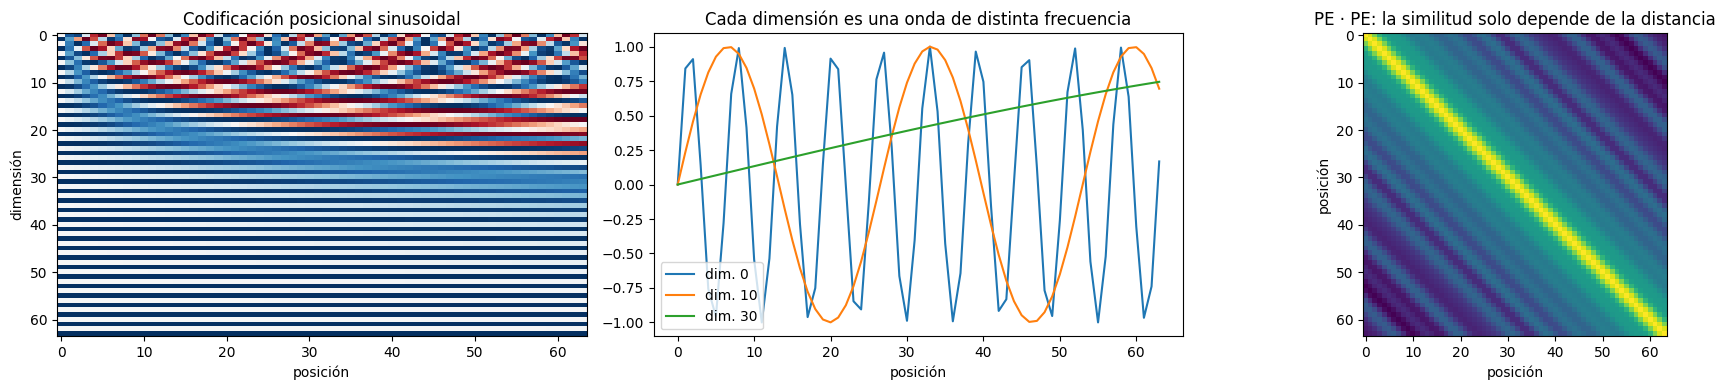

In [2]:
def sinusoidal_pe(n_pos, d):
    pos = np.arange(n_pos)[:, None]
    i = np.arange(0, d, 2)[None, :]
    angle = pos / (10000 ** (i / d))
    pe = np.zeros((n_pos, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
    return pe

pe = sinusoidal_pe(64, 64)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].imshow(pe.T, cmap="RdBu", aspect="auto"); axes[0].set_xlabel("posición"); axes[0].set_ylabel("dimensión")
axes[0].set_title("Codificación posicional sinusoidal")
for dim in [0, 10, 30]:
    axes[1].plot(pe[:, dim], label=f"dim. {dim}")
axes[1].legend(); axes[1].set_xlabel("posición"); axes[1].set_title("Cada dimensión es una onda de distinta frecuencia")
axes[2].imshow(pe @ pe.T, cmap="viridis"); axes[2].set_title("PE · PE: la similitud solo depende de la distancia")
axes[2].set_xlabel("posición"); axes[2].set_ylabel("posición")
plt.tight_layout(); plt.show()

## 3. Atención de producto escalar escalado, paso a paso

El vector $x_i$ de cada token se proyecta de tres formas con matrices aprendidas:

* **Consulta** (query) $q_i = x_i W_Q$: "¿qué estoy buscando?"
* **Clave** (key) $k_j = x_j W_K$: "¿qué contengo?" (un anuncio)
* **Valor** (value) $v_j = x_j W_V$: "¿qué entregaré si me eliges?"

El token $i$ compara su consulta con todas las claves, convierte las puntuaciones en pesos con softmax y toma la media ponderada de los valores:

$$ \text{Atención}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V $$

Es una **búsqueda en diccionario suave y derivable**: en lugar de devolver el valor de la única clave que coincide, devuelve una mezcla ponderada según lo bien que coincide cada clave.

Ejecutémosla sobre una frase de 6 tokens con pesos aleatorios para que cada paso intermedio sea visible.

X: (6, 8)  Q,K,V: (6, 4)  puntuaciones: (6, 6)  salida: (6, 4)
sumas por fila de A: [1. 1. 1. 1. 1. 1.]


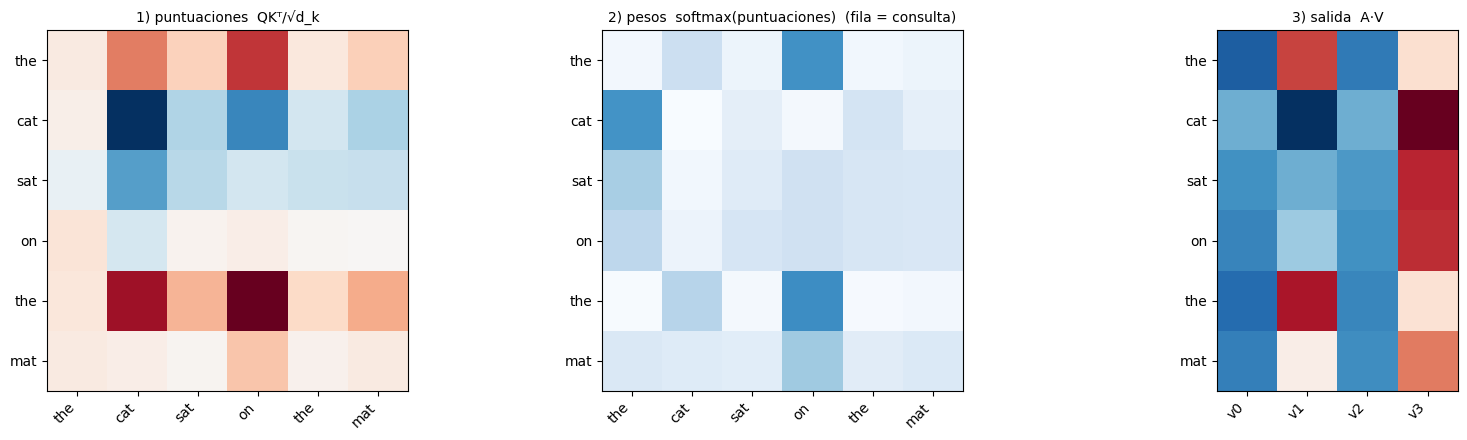

In [3]:
tokens = ["the", "cat", "sat", "on", "the", "mat"]
vocab = sorted(set(tokens))
d_model, d_k = 8, 4
E = np.random.randn(len(vocab), d_model)                     # tabla de embeddings
X = np.array([E[vocab.index(t)] for t in tokens]) + sinusoidal_pe(len(tokens), d_model)
W_Q, W_K, W_V = (np.random.randn(d_model, d_k) / np.sqrt(d_model) for _ in range(3))

Q, K, V = X @ W_Q, X @ W_K, X @ W_V
scores = Q @ K.T / np.sqrt(d_k)                              # (6, 6): cada consulta frente a cada clave
A = softmax(scores, axis=-1)                                  # cada fila suma 1
out = A @ V                                                   # (6, 4): nueva representación por token

print("X:", X.shape, " Q,K,V:", Q.shape, " puntuaciones:", scores.shape, " salida:", out.shape)
print("sumas por fila de A:", A.sum(axis=1))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
show_matrix(axes[0], scores, tokens, tokens, "1) puntuaciones  QKᵀ/√d_k", cmap="RdBu_r")
show_matrix(axes[1], A, tokens, tokens, "2) pesos  softmax(puntuaciones)  (fila = consulta)", vmin=0, vmax=1)
show_matrix(axes[2], out, [f"v{i}" for i in range(d_k)], tokens, "3) salida  A·V", cmap="RdBu_r")
plt.tight_layout(); plt.show()

### ¿Por qué dividir entre $\sqrt{d_k}$?

Si las entradas de $q$ y $k$ tienen varianza unitaria, $q\cdot k$ es una suma de $d_k$ términos y tiene varianza $d_k$. Con un $d_k$ grande las puntuaciones se vuelven enormes, softmax colapsa a un vector one-hot y su gradiente se vuelve casi cero (el problema de saturación del notebook 01). Dividir entre $\sqrt{d_k}$ devuelve la varianza a 1.

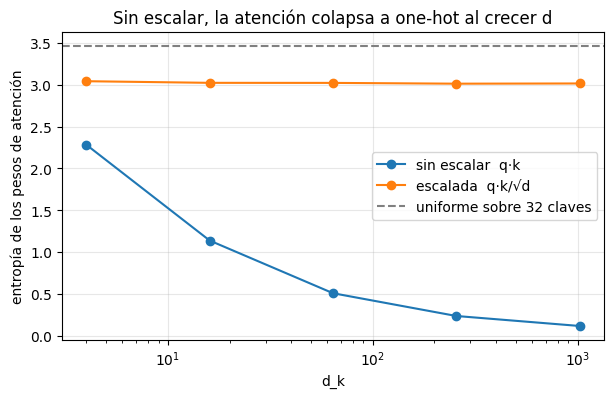

In [4]:
dims = [4, 16, 64, 256, 1024]
ent_raw, ent_scaled = [], []
for d in dims:
    q, k = np.random.randn(1000, d), np.random.randn(1000, 32, d)
    s = np.einsum("nd,nkd->nk", q, k)
    for store, ss in [(ent_raw, s), (ent_scaled, s / np.sqrt(d))]:
        p = softmax(ss)
        store.append(-(p * np.log(p + 1e-12)).sum(1).mean())
plt.figure(figsize=(7, 4))
plt.semilogx(dims, ent_raw, "o-", label="sin escalar  q·k"); plt.semilogx(dims, ent_scaled, "o-", label="escalada  q·k/√d")
plt.axhline(np.log(32), color="gray", ls="--", label="uniforme sobre 32 claves")
plt.xlabel("d_k"); plt.ylabel("entropía de los pesos de atención"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Sin escalar, la atención colapsa a one-hot al crecer d"); plt.show()

### La atención sin posiciones no ve el orden

Si se barajan los tokens de entrada, las salidas se barajan exactamente igual, pero el vector de salida de cada token no cambia. La autoatención es **equivariante a permutaciones**; de ahí la necesidad de las codificaciones posicionales.

In [5]:
def attention(Xin):
    q, k, v = Xin @ W_Q, Xin @ W_K, Xin @ W_V
    return softmax(q @ k.T / np.sqrt(d_k)) @ v

X_nopos = np.array([E[vocab.index(t)] for t in tokens])
perm = np.random.permutation(len(tokens))
print("permutación:", perm)
print("atención(X barajada) == atención(X) barajada:", np.allclose(attention(X_nopos[perm]), attention(X_nopos)[perm]))

permutación: [1 0 4 5 3 2]
atención(X barajada) == atención(X) barajada: True


## 4. Máscaras

* **Máscara de relleno:** las secuencias de un lote se rellenan hasta la misma longitud; no se debe atender a las posiciones de relleno.
* **Máscara causal (de anticipación):** en un decodificador o en GPT, el token $i$ solo puede atender a los tokens $\le i$; si no, podría "hacer trampa" mirando la palabra que se supone que debe predecir.

Ambas se aplican poniendo las puntuaciones prohibidas a $-\infty$ **antes** del softmax, de modo que sus pesos queden exactamente en 0.

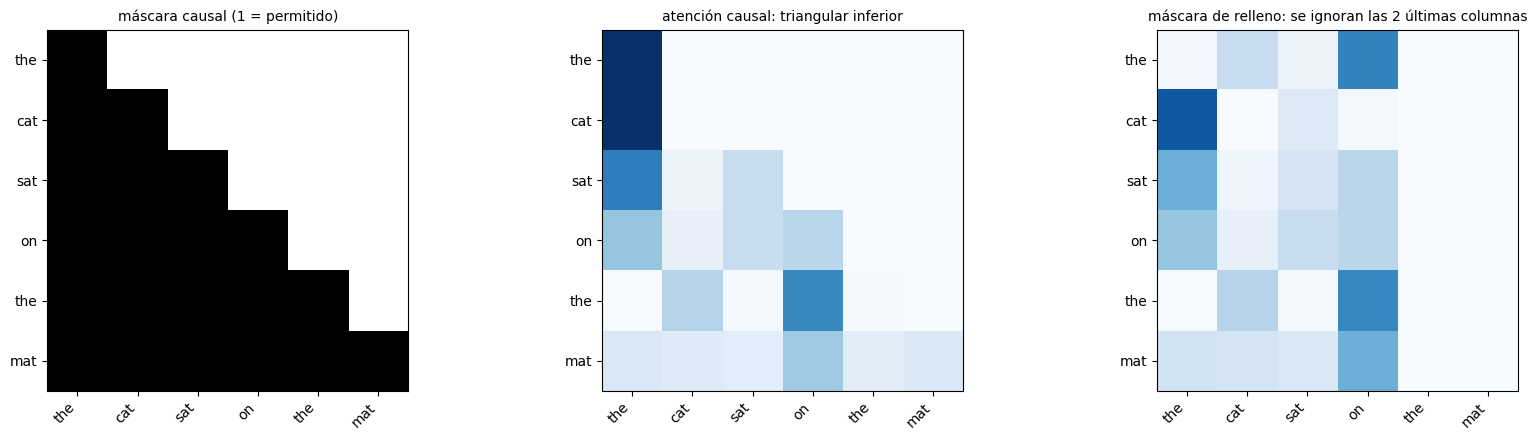

In [6]:
n = len(tokens)
causal = np.tril(np.ones((n, n), dtype=bool))
A_causal = softmax(np.where(causal, scores, -np.inf))

pad = np.array([True, True, True, True, False, False])      # supongamos que los dos últimos tokens son relleno
A_pad = softmax(np.where(pad[None, :], scores, -np.inf))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
show_matrix(axes[0], causal.astype(float), tokens, tokens, "máscara causal (1 = permitido)", cmap="Greys")
show_matrix(axes[1], A_causal, tokens, tokens, "atención causal: triangular inferior", vmin=0, vmax=1)
show_matrix(axes[2], A_pad, tokens, tokens, "máscara de relleno: se ignoran las 2 últimas columnas", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

## 5. Atención multicabeza

Un solo patrón de atención por capa es limitante: un token puede necesitar mirar a la vez su palabra anterior (sintaxis) **y** un sustantivo relacionado que está lejos (significado). La **atención multicabeza** ejecuta $h$ operaciones de atención en paralelo, cada una en un subespacio más pequeño de tamaño $d_k = d_{model}/h$, y después las concatena y las mezcla con una proyección de salida $W_O$:

$$ \text{MHA}(X) = \text{Concat}(\text{cabeza}_1,\dots,\text{cabeza}_h)\,W_O, \qquad \text{cabeza}_i = \text{Atención}(XW_Q^{(i)}, XW_K^{(i)}, XW_V^{(i)}) $$

En la práctica todas las cabezas se calculan con **una sola** multiplicación de matrices grande y un cambio de forma, como abajo. El coste es el mismo que el de una sola cabeza de anchura completa.

entrada (6, 8) -> salida (6, 8) | mapas de atención (4, 6, 6) (cabezas, consulta, clave)


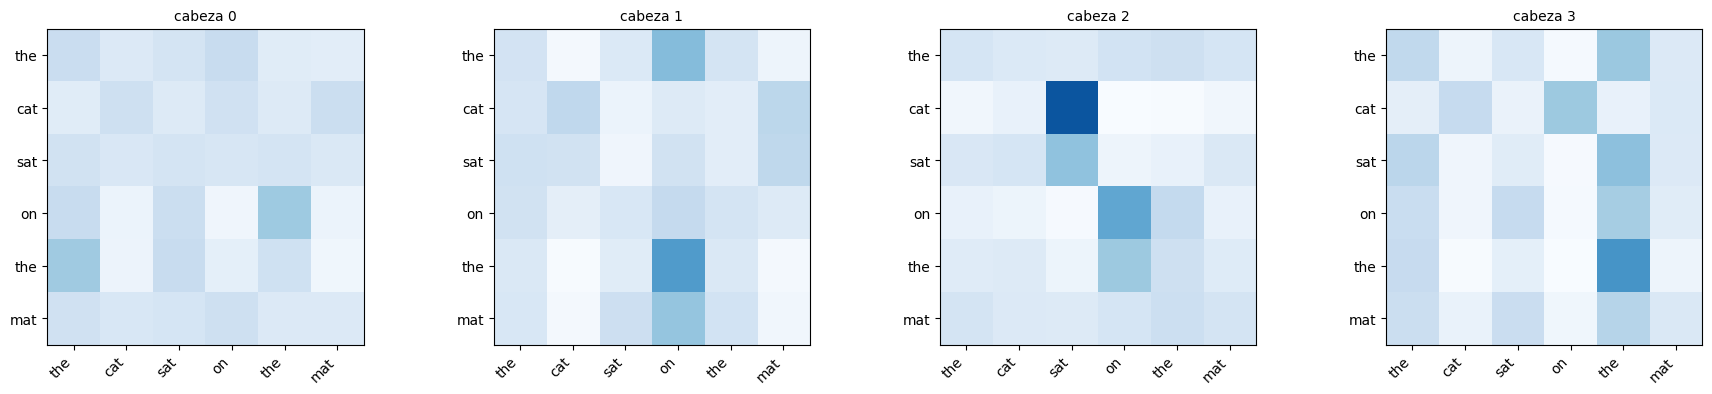

In [7]:
def multi_head_attention(X, Wq, Wk, Wv, Wo, n_heads, mask=None):
    n, d = X.shape
    dh = d // n_heads
    def split(M):                                   # (n, d) -> (heads, n, dh)
        return M.reshape(n, n_heads, dh).transpose(1, 0, 2)
    Q, K, V = split(X @ Wq), split(X @ Wk), split(X @ Wv)
    scores = Q @ K.transpose(0, 2, 1) / np.sqrt(dh)  # (heads, n, n)
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)
    A = softmax(scores)
    heads = A @ V                                   # (heads, n, dh)
    concat = heads.transpose(1, 0, 2).reshape(n, d) # de vuelta a (n, d)
    return concat @ Wo, A

d_model, n_heads = 8, 4
Wq, Wk, Wv, Wo = (np.random.randn(d_model, d_model) / np.sqrt(d_model) for _ in range(4))
Y, A_heads = multi_head_attention(X, Wq, Wk, Wv, Wo, n_heads)
print("entrada", X.shape, "-> salida", Y.shape, "| mapas de atención", A_heads.shape, "(cabezas, consulta, clave)")
fig, axes = plt.subplots(1, n_heads, figsize=(18, 4))
for h, ax in enumerate(axes):
    show_matrix(ax, A_heads[h], tokens, tokens, f"cabeza {h}", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

## 6. La red de propagación hacia adelante (MLP)

Después de que la atención *mezcla información entre tokens*, cada token pasa **por separado** por el mismo MLP de dos capas (notebook 02), normalmente 4 veces más ancho en el medio:

$$ \text{FFN}(x) = W_2\,\text{GELU}(W_1 x + b_1) + b_2, \qquad W_1 \in \mathbb{R}^{4d\times d},\; W_2 \in \mathbb{R}^{d\times 4d} $$

Formas de pensarlo:
* **Atención = comunicación, MLP = cálculo.** La atención mueve la información de un lado a otro; el MLP la transforma.
* **Memoria clave-valor** (Geva et al., 2021): los pesos de entrada de cada neurona oculta (una fila de $W_1$) actúan como una *clave* que detecta un patrón; sus pesos de salida (una columna de $W_2$) son el *valor* que se escribe en el token cuando el patrón se activa. Se cree que buena parte del conocimiento factual de un modelo de lenguaje vive aquí.
* Contiene aproximadamente **dos tercios** de los parámetros de un transformer (sección 10).

"Por posición" significa que se aplican los mismos pesos a cada token por separado: la celda de abajo comprueba que procesar los tokens uno a uno da el mismo resultado que procesar la secuencia completa.

In [8]:
def gelu(x):
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x ** 3)))   # la aproximación de GPT-2

d_ff = 4 * d_model
W1, b1 = np.random.randn(d_model, d_ff) / np.sqrt(d_model), np.zeros(d_ff)
W2, b2 = np.random.randn(d_ff, d_model) / np.sqrt(d_ff), np.zeros(d_model)
ffn = lambda x: gelu(x @ W1 + b1) @ W2 + b2

whole = ffn(X)
one_by_one = np.stack([ffn(X[i:i + 1])[0] for i in range(len(X))])
print("FFN aplicada a la secuencia == FFN aplicada a cada token por separado:", np.allclose(whole, one_by_one))
print(f"parámetros de la FFN: {W1.size + b1.size + W2.size + b2.size}  frente a  parámetros de la atención: {4 * d_model * d_model}")

FFN aplicada a la secuencia == FFN aplicada a cada token por separado: True
parámetros de la FFN: 552  frente a  parámetros de la atención: 256


## 7. El flujo residual y LayerNorm: un bloque transformer completo

Dos ingredientes más hacen entrenables las pilas profundas:

* **Conexiones residuales** $x \leftarrow x + \text{Subcapa}(x)$. Cada subcapa solo *suma* una actualización a un vector en curso llamado **flujo residual** (residual stream). Los gradientes atraviesan directamente las sumas (la misma idea que el estado de celda de la LSTM y que ResNet), así que se pueden entrenar más de 100 capas.
* La **normalización de capa** reescala cada vector de token a media cero y varianza unitaria, y después aplica una escala aprendida $\gamma$ y un desplazamiento $\beta$. Mantiene las activaciones en un rango sano.

Los modelos modernos usan la disposición **pre-LN** (normalizar *antes* de cada subcapa), que es más estable que la post-LN original:

```
x ─┬─► LayerNorm ─► Atención multicabeza ─┐
   └──────────────────────────────────────(+)─┬─► LayerNorm ─► FFN (MLP) ─┐
                                              └───────────────────────────(+)─► siguiente bloque
```

In [9]:
def layer_norm(x, gamma, beta, eps=1e-5):
    mu = x.mean(axis=-1, keepdims=True)
    var = x.var(axis=-1, keepdims=True)
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

def transformer_block(x, p, mask=None):
    a, attn = multi_head_attention(layer_norm(x, *p["ln1"]), *p["attn"], n_heads=p["heads"], mask=mask)
    x = x + a                                         # residual 1: la atención suma al flujo
    x = x + p["ffn"](layer_norm(x, *p["ln2"]))        # residual 2: el MLP suma al flujo
    return x, attn

params = {"ln1": (np.ones(d_model), np.zeros(d_model)), "ln2": (np.ones(d_model), np.zeros(d_model)),
          "attn": (Wq, Wk, Wv, Wo), "heads": n_heads, "ffn": ffn}
h = X
for layer in range(3):                               # pesos compartidos por brevedad; los modelos reales usan pesos distintos en cada capa
    h_new, _ = transformer_block(h, params, mask=causal)
    print(f"bloque {layer}: forma {h_new.shape}, tamaño de la actualización ‖Δ‖ = {np.linalg.norm(h_new - h):.2f}")
    h = h_new

# Comparamos nuestra LayerNorm con la de PyTorch
x_t = torch.randn(5, 8)
ours = layer_norm(x_t.numpy(), np.ones(8), np.zeros(8))
print("LayerNorm coincide con PyTorch:", np.allclose(ours, F.layer_norm(x_t, (8,)).numpy(), atol=1e-5))

bloque 0: forma (6, 8), tamaño de la actualización ‖Δ‖ = 5.29
bloque 1: forma (6, 8), tamaño de la actualización ‖Δ‖ = 5.11
bloque 2: forma (6, 8), tamaño de la actualización ‖Δ‖ = 5.46
LayerNorm coincide con PyTorch: True


## 8. Un transformer completo en PyTorch, entrenado para ordenar números

Ahora lo de verdad: un **transformer codificador-decodificador** exactamente como en el artículo de 2017 (con pre-LN), escrito desde cero con capas `nn.Linear`. Sin `nn.Transformer`. Los módulos de atención guardan sus pesos para que podamos inspeccionarlos después.

**Tarea:** la entrada son 10 dígitos aleatorios y la salida, los mismos dígitos ordenados. *"3 9 1 1 7 0 4 2 8 5"* → *"0 1 1 2 3 4 5 7 8 9"*. Ordenar es un buen juguete porque:
* **requiere** atención: cada posición de salida debe encontrar el $k$-ésimo dígito más pequeño, esté donde esté,
* hay $10^{10}$ entradas posibles, así que el modelo no puede memorizar; debe aprender el algoritmo,
* los patrones de atención aprendidos son interpretables.

```
 dígitos de origen ─► Embedding + PE ─► [Bloque codificador] × N ─► memoria ─────────────┐
                                        (autoatención + MLP)                             │
                                                                                         ▼
 <sos> + ordenados[:-1] ─► Embedding + PE ─► [Bloque decodificador] × N ─► Lineal ─► softmax sobre dígitos
                                             (autoatención causal + atención cruzada a la memoria + MLP)
```

In [10]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dh = n_heads, d_model // n_heads
        self.Wq, self.Wk, self.Wv, self.Wo = (nn.Linear(d_model, d_model) for _ in range(4))
        self.last_attn = None
    def forward(self, x_q, x_kv, mask=None):
        B, Tq, D = x_q.shape
        Tk = x_kv.shape[1]
        q = self.Wq(x_q).view(B, Tq, self.h, self.dh).transpose(1, 2)    # (B, h, Tq, dh)
        k = self.Wk(x_kv).view(B, Tk, self.h, self.dh).transpose(1, 2)
        v = self.Wv(x_kv).view(B, Tk, self.h, self.dh).transpose(1, 2)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dh)            # (B, h, Tq, Tk)
        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))
        attn = scores.softmax(-1)
        self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, Tq, D)
        return self.Wo(out)

class FeedForward(nn.Module):
    def __init__(self, d_model, mult=4):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, mult * d_model), nn.GELU(), nn.Linear(mult * d_model, d_model))
    def forward(self, x):
        return self.net(x)

class EncoderBlock(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.ln1, self.attn, self.ln2, self.ffn = nn.LayerNorm(d), MultiHeadAttention(d, h), nn.LayerNorm(d), FeedForward(d)
    def forward(self, x):
        y = self.ln1(x)
        x = x + self.attn(y, y)
        return x + self.ffn(self.ln2(x))

class DecoderBlock(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.ln1, self.self_attn = nn.LayerNorm(d), MultiHeadAttention(d, h)
        self.ln2, self.cross_attn = nn.LayerNorm(d), MultiHeadAttention(d, h)
        self.ln3, self.ffn = nn.LayerNorm(d), FeedForward(d)
    def forward(self, x, memory, causal_mask):
        y = self.ln1(x)
        x = x + self.self_attn(y, y, causal_mask)                  # solo mira las salidas anteriores
        x = x + self.cross_attn(self.ln2(x), memory)               # mira el origen codificado
        return x + self.ffn(self.ln3(x))

class Transformer(nn.Module):
    def __init__(self, vocab, d=64, heads=4, n_enc=2, n_dec=2, max_len=32):
        super().__init__()
        self.src_emb, self.tgt_emb = nn.Embedding(vocab, d), nn.Embedding(vocab, d)
        self.register_buffer("pe", torch.tensor(sinusoidal_pe(max_len, d), dtype=torch.float32))
        self.enc = nn.ModuleList(EncoderBlock(d, heads) for _ in range(n_enc))
        self.dec = nn.ModuleList(DecoderBlock(d, heads) for _ in range(n_dec))
        self.ln_enc, self.ln_dec = nn.LayerNorm(d), nn.LayerNorm(d)
        self.out = nn.Linear(d, vocab)
        self.d = d
    def encode(self, src):
        x = self.src_emb(src) * math.sqrt(self.d) + self.pe[:src.shape[1]]
        for blk in self.enc:
            x = blk(x)
        return self.ln_enc(x)
    def decode(self, tgt_in, memory):
        T = tgt_in.shape[1]
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt_in.device))
        x = self.tgt_emb(tgt_in) * math.sqrt(self.d) + self.pe[:T]
        for blk in self.dec:
            x = blk(x, memory, causal)
        return self.out(self.ln_dec(x))
    def forward(self, src, tgt_in):
        return self.decode(tgt_in, self.encode(src))

N_DIGITS, SEQ, SOS = 10, 10, 10
VOCAB = N_DIGITS + 1

def make_batch(B):
    src = torch.randint(0, N_DIGITS, (B, SEQ))
    tgt = src.sort(dim=1).values
    tgt_in = torch.cat([torch.full((B, 1), SOS), tgt[:, :-1]], dim=1)     # desplazamiento a la derecha: teacher forcing
    return src, tgt_in, tgt

torch.manual_seed(0)
model = Transformer(VOCAB)
print(f"parámetros: {sum(p.numel() for p in model.parameters()):,}")
src, tgt_in, tgt = make_batch(2)
print("origen de ejemplo       :", src[0].tolist())
print("entrada del decodificador:", tgt_in[0].tolist(), "(10 = <sos>)")
print("objetivo                :", tgt[0].tolist())

parámetros: 235,851
origen de ejemplo       : [8, 8, 5, 5, 5, 0, 6, 7, 1, 6]
entrada del decodificador: [10, 0, 1, 5, 5, 5, 6, 6, 7, 8] (10 = <sos>)
objetivo                : [0, 1, 5, 5, 5, 6, 6, 7, 8, 8]


paso    0  pérdida 2.4649  (0 s)


paso  300  pérdida 0.0492  (81 s)


paso  600  pérdida 0.0290  (111 s)


paso  900  pérdida 0.0024  (141 s)


paso 1199  pérdida 0.0018  (171 s)


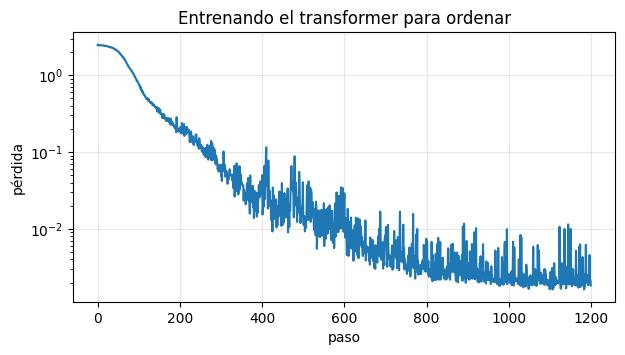

In [11]:
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
steps = 1200
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=steps, pct_start=0.1)   # calentamiento y después decaimiento
t0, losses = time.time(), []
for step in range(steps):
    src, tgt_in, tgt = make_batch(128)
    logits = model(src, tgt_in)
    loss = F.cross_entropy(logits.reshape(-1, VOCAB), tgt.reshape(-1))
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    losses.append(loss.item())
    if step % 300 == 0 or step == steps - 1:
        print(f"paso {step:4d}  pérdida {loss.item():.4f}  ({time.time() - t0:.0f} s)")
plt.figure(figsize=(7, 3.5)); plt.semilogy(losses); plt.xlabel("paso"); plt.ylabel("pérdida"); plt.grid(alpha=0.3)
plt.title("Entrenando el transformer para ordenar"); plt.show()

In [12]:
@torch.no_grad()
def greedy_sort(model, src):
    memory = model.encode(src)
    out = torch.full((src.shape[0], 1), SOS)
    for _ in range(SEQ):                                   # autorregresivo: un dígito cada vez
        nxt = model.decode(out, memory)[:, -1].argmax(-1, keepdim=True)
        out = torch.cat([out, nxt], dim=1)
    return out[:, 1:]

model.eval()
torch.manual_seed(123)
src, _, tgt = make_batch(2000)
pred = greedy_sort(model, src)
print(f"secuencias totalmente correctas: {(pred == tgt).all(1).float().mean():.1%}   exactitud por dígito: {(pred == tgt).float().mean():.2%}")
for i in range(4):
    print("entrada", src[i].tolist(), "\nsalida ", pred[i].tolist(), "✓" if (pred[i] == tgt[i]).all() else "✗")

secuencias totalmente correctas: 99.8%   exactitud por dígito: 99.97%
entrada [2, 9, 2, 0, 0, 2, 6, 7, 9, 4] 
salida  [0, 0, 2, 2, 2, 4, 6, 7, 9, 9] ✓
entrada [1, 1, 6, 1, 2, 9, 4, 1, 3, 0] 
salida  [0, 1, 1, 1, 1, 2, 3, 4, 6, 9] ✓
entrada [0, 6, 5, 7, 9, 2, 1, 6, 0, 6] 
salida  [0, 0, 1, 2, 5, 6, 6, 6, 7, 9] ✓
entrada [6, 5, 3, 9, 4, 6, 1, 8, 0, 5] 
salida  [0, 1, 3, 4, 5, 5, 6, 6, 8, 9] ✓


## 9. Cómo se propaga la atención

### 9a. Qué mira cada capa y cada cabeza

Ejecutamos un ejemplo y dibujamos cada mapa de atención:
* **Autoatención del codificador** (entrada ↔ entrada): cómo intercambian información los tokens de origen, por ejemplo para averiguar la posición de cada dígito en el orden.
* **Atención cruzada del decodificador** (salida → entrada): para la posición de salida $k$, qué posiciones de origen lee. Al ordenar, deberías ver que cada paso de salida se fija en la posición o posiciones de entrada que contienen el dígito que está a punto de escribir (un "puntero" aprendido), a menudo con algo de peso en su vecino en el orden, lo que ayuda al modelo a decidir cuándo pasar al siguiente valor.

entrada: [7, 2, 9, 0, 4, 4, 1, 8, 3, 6] 
salida : [0, 1, 2, 3, 4, 4, 6, 7, 8, 9]


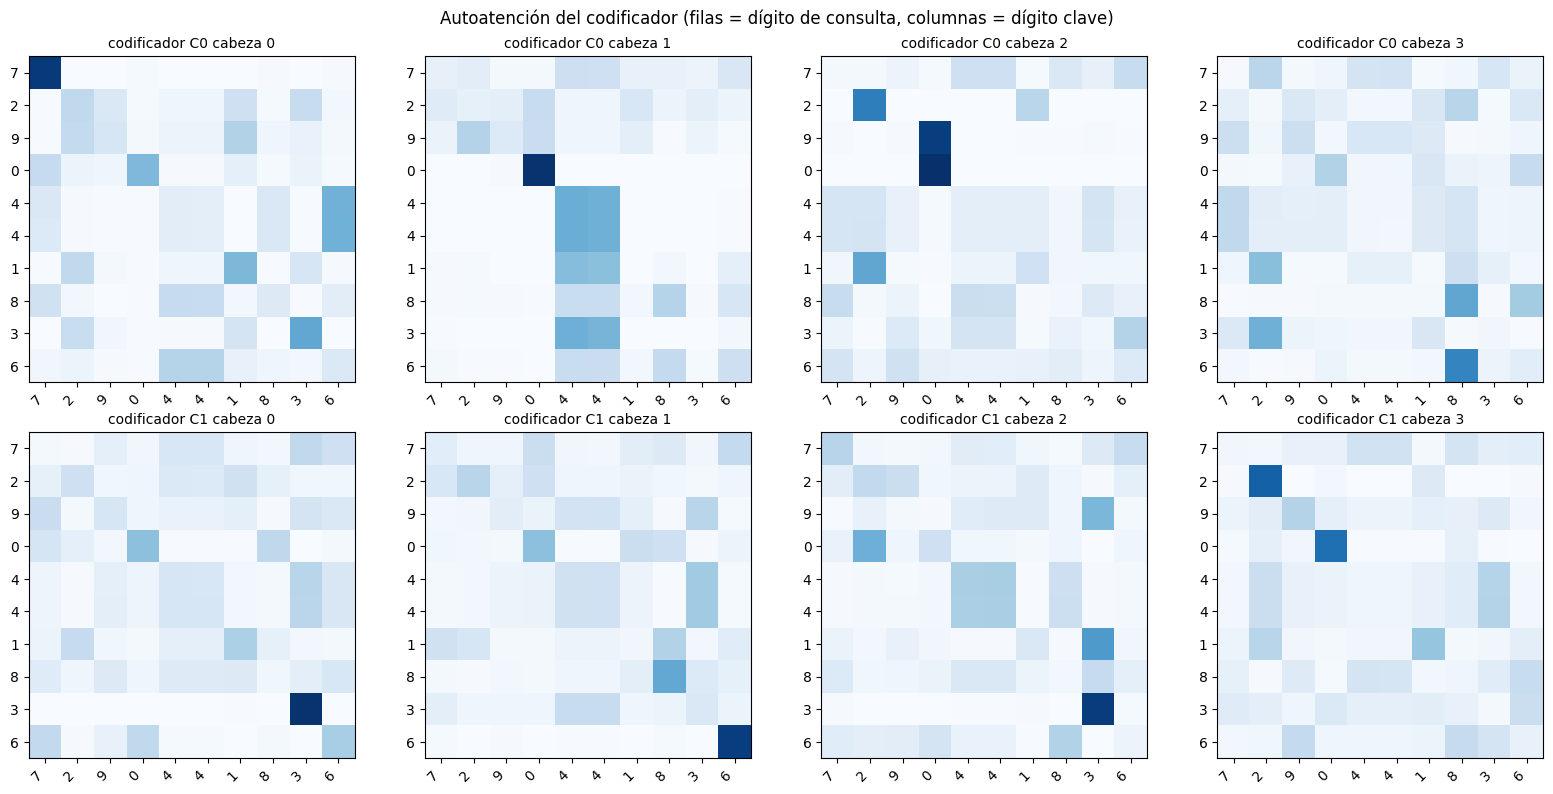

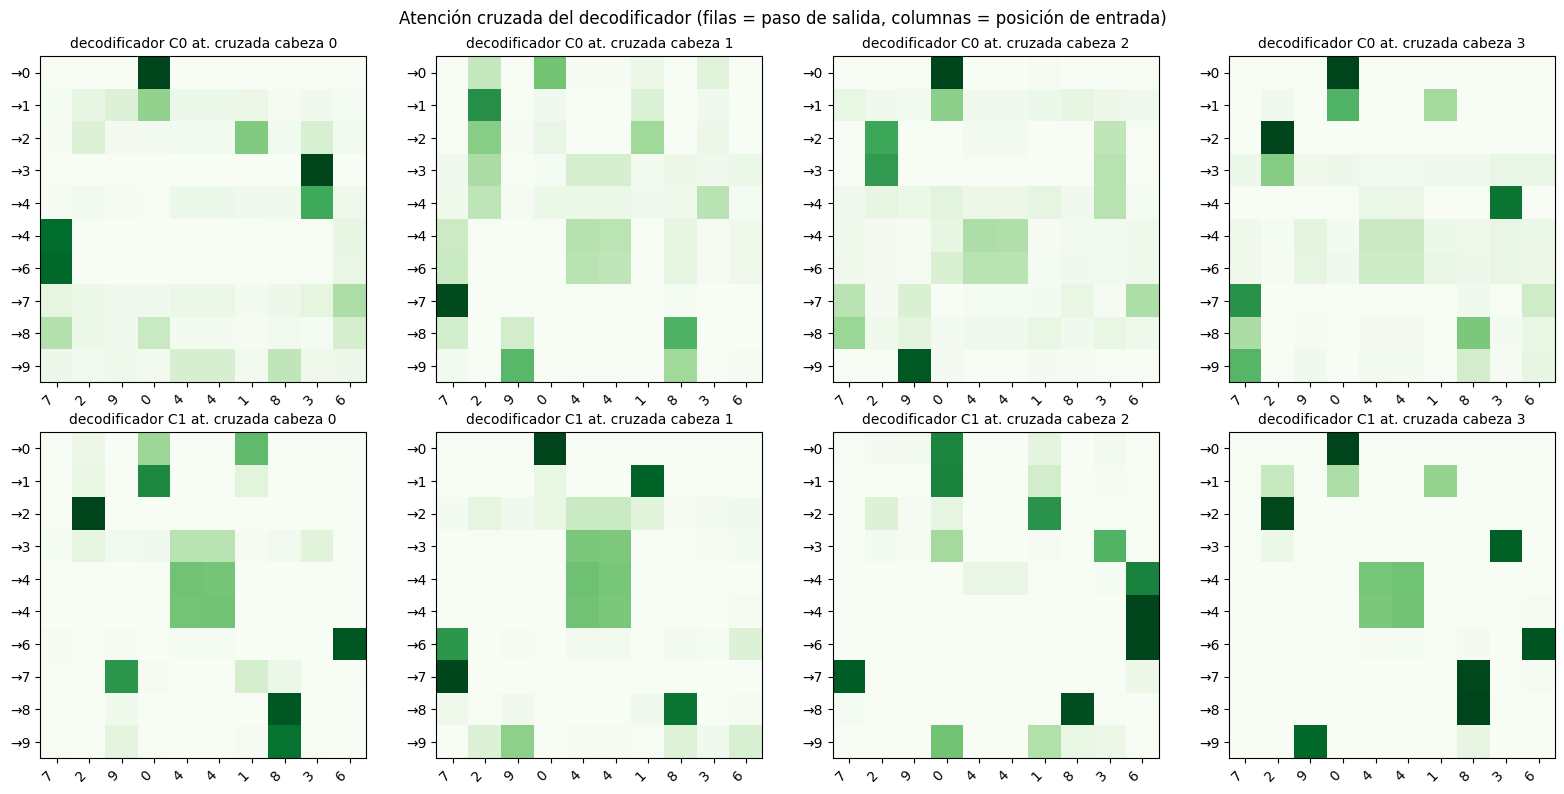

In [13]:
example = torch.tensor([[7, 2, 9, 0, 4, 4, 1, 8, 3, 6]])
with torch.no_grad():
    memory = model.encode(example)
    res = greedy_sort(model, example)
    tgt_in = torch.cat([torch.tensor([[SOS]]), res[:, :-1]], dim=1)
    model.decode(tgt_in, memory)                         # rellena last_attn para toda la secuencia decodificada
src_lbl = [f"{d}" for d in example[0].tolist()]
out_lbl = [f"→{d}" for d in res[0].tolist()]
print("entrada:", example[0].tolist(), "\nsalida :", res[0].tolist())

H = model.enc[0].attn.h
fig, axes = plt.subplots(2, H, figsize=(4 * H, 8))
for l, blk in enumerate(model.enc):
    for h in range(H):
        show_matrix(axes[l, h], blk.attn.last_attn[0, h], src_lbl, src_lbl, f"codificador C{l} cabeza {h}", vmin=0, vmax=1)
fig.suptitle("Autoatención del codificador (filas = dígito de consulta, columnas = dígito clave)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, H, figsize=(4 * H, 8))
for l, blk in enumerate(model.dec):
    for h in range(H):
        show_matrix(axes[l, h], blk.cross_attn.last_attn[0, h], src_lbl, out_lbl, f"decodificador C{l} at. cruzada cabeza {h}", cmap="Greens", vmin=0, vmax=1)
fig.suptitle("Atención cruzada del decodificador (filas = paso de salida, columnas = posición de entrada)"); plt.tight_layout(); plt.show()

### 9b. Rollout de atención: seguir la información a través de la pila

Un solo mapa de atención solo muestra un salto. Después de la capa 1, el vector del token $j$ ya contiene información de otros tokens, así que cuando la capa 2 atiende a $j$ también lee indirectamente *esos* tokens. El **rollout de atención** (Abnar y Zuidema, 2020) lo sigue multiplicando los mapas de cada capa. Por la conexión residual, cada capa transmite también la mitad del token original, lo que modelamos como $\tfrac12 A + \tfrac12 I$:

$$ R^{(L)} = \prod_{\ell=1}^{L} \left(\tfrac12 \bar A^{(\ell)} + \tfrac12 I\right) \qquad (\bar A = \text{media sobre las cabezas}) $$

La fila $i$ de $R$ estima cuánto de cada token de entrada ha llegado a la representación final del token $i$.

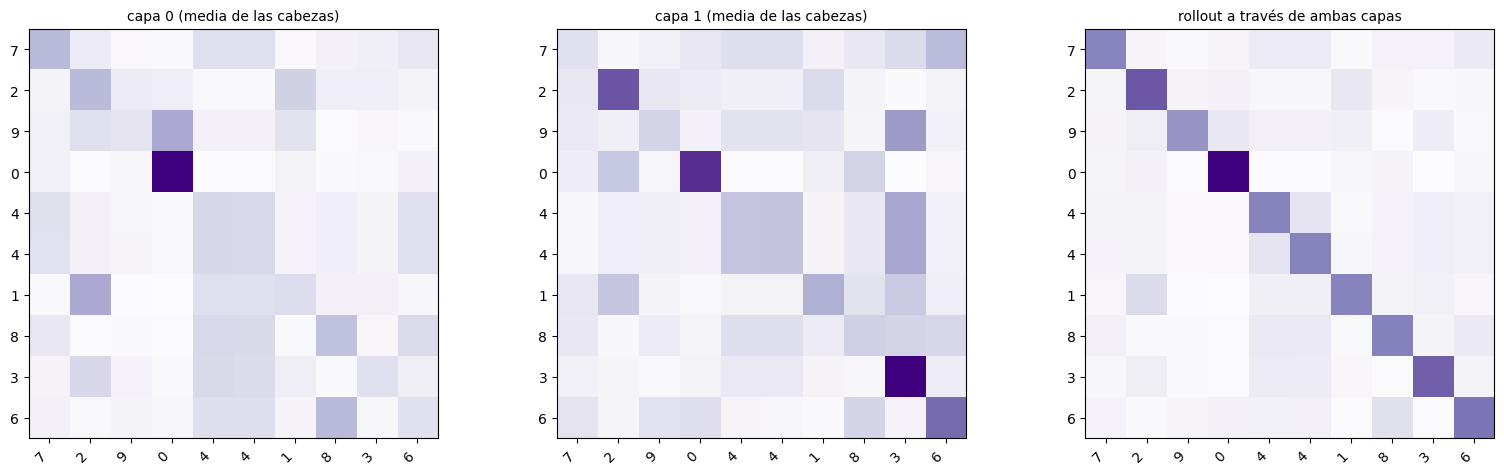

In [14]:
def rollout(attn_maps):
    R = torch.eye(attn_maps[0].shape[-1])
    for A in attn_maps:
        A_bar = A.mean(0)                                       # promedio de las cabezas
        A_res = 0.5 * A_bar + 0.5 * torch.eye(A_bar.shape[0])   # tiene en cuenta el camino residual
        A_res = A_res / A_res.sum(-1, keepdim=True)
        R = A_res @ R
    return R

enc_maps = [blk.attn.last_attn[0] for blk in model.enc]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
show_matrix(axes[0], enc_maps[0].mean(0), src_lbl, src_lbl, "capa 0 (media de las cabezas)", cmap="Purples")
show_matrix(axes[1], enc_maps[1].mean(0), src_lbl, src_lbl, "capa 1 (media de las cabezas)", cmap="Purples")
show_matrix(axes[2], rollout(enc_maps), src_lbl, src_lbl, "rollout a través de ambas capas", cmap="Purples")
plt.tight_layout(); plt.show()

### 9c. Flujo del gradiente: ¿qué entradas influyen realmente en una salida?

Los pesos de atención nos dicen por dónde *podría* fluir la información. Los gradientes nos dicen a qué es realmente *sensible* la salida. Calculamos $\left\|\partial\, \text{logit}_k / \partial\, \text{embedding}_j\right\|$ para cada paso de salida $k$ y cada posición de entrada $j$. Es retropropagación (notebook 02) usada para interpretar, y fluye exactamente por los caminos de atención visualizados arriba.

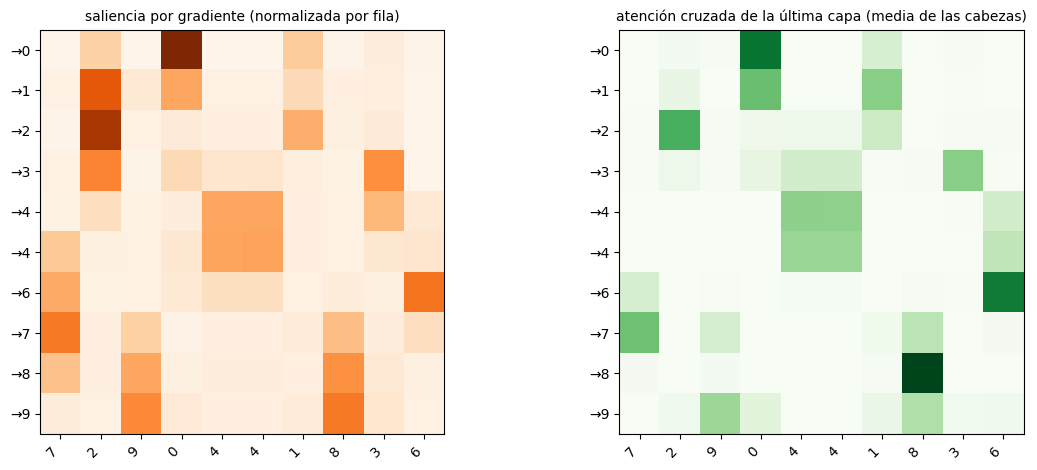

In [15]:
model.zero_grad()
emb = (model.src_emb(example) * math.sqrt(model.d)).detach().requires_grad_(True)
x = emb + model.pe[:SEQ]
for blk in model.enc:
    x = blk(x)
memory = model.ln_enc(x)
logits = model.decode(tgt_in, memory)                        # (1, SEQ, VOCAB)

saliency = torch.zeros(SEQ, SEQ)
for k in range(SEQ):
    chosen = logits[0, k, res[0, k]]                         # el logit del dígito que realmente escribió
    g, = torch.autograd.grad(chosen, emb, retain_graph=True)
    saliency[k] = g[0].norm(dim=-1)
saliency = saliency / saliency.sum(1, keepdim=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
show_matrix(axes[0], saliency, src_lbl, out_lbl, "saliencia por gradiente (normalizada por fila)", cmap="Oranges")
show_matrix(axes[1], model.dec[-1].cross_attn.last_attn[0].mean(0), src_lbl, out_lbl, "atención cruzada de la última capa (media de las cabezas)", cmap="Greens")
plt.tight_layout(); plt.show()

Cómo leer las gráficas:
* La atención cruzada y la saliencia coinciden en gran medida: cada paso de salida depende sobre todo de la entrada que contiene el dígito que se está escribiendo y de sus vecinos en el orden (el valor anterior o el siguiente).
* No coinciden del todo, y esa es la lección: la atención muestra por dónde se *enruta* la información, el gradiente muestra a qué es *sensible* la decisión. Para saber que el "4" va en quinto lugar, el modelo debe tener en cuenta cuántos dígitos menores hay; ese conteo ocurre en la autoatención del codificador y en los MLP, y aparece como una sensibilidad repartida.
* Los resultados varían un poco entre ejecuciones de entrenamiento (semillas aleatorias distintas aprenden estrategias distintas pero igual de correctas).

## 10. Dónde viven los parámetros

Para un bloque con anchura de modelo $d$ y expansión 4 en el MLP:

| Componente | Parámetros | Proporción |
|---|---|---|
| Atención $W_Q, W_K, W_V, W_O$ | $4d^2$ | ≈ 1/3 |
| Propagación hacia adelante $W_1, W_2$ | $2 \cdot d \cdot 4d = 8d^2$ | ≈ 2/3 |
| LayerNorm, sesgos | $O(d)$ | despreciable |

Así que un bloque tiene unos $12d^2$ parámetros, la fórmula que usaremos para GPT en el notebook 08.

In [16]:
def count(m): return sum(p.numel() for p in m.parameters())
blk = model.enc[0]
attn_p, ffn_p, ln_p = count(blk.attn), count(blk.ffn), count(blk.ln1) + count(blk.ln2)
print(f"bloque codificador (d=64): atención {attn_p:,}  FFN {ffn_p:,}  LayerNorm {ln_p:,}")
print(f"proporción de la FFN: {ffn_p / (attn_p + ffn_p + ln_p):.0%},  12·d² = {12 * 64 ** 2:,}")
for name, d, L in [("GPT-2 small", 768, 12), ("GPT-2 XL", 1600, 48), ("GPT-3", 12288, 96)]:
    print(f"{name:12s} d={d:5d} layers={L:3d}  ->  12·L·d² ≈ {12 * L * d * d / 1e9:6.2f} mil millones de parámetros en los bloques")

bloque codificador (d=64): atención 16,640  FFN 33,088  LayerNorm 256
proporción de la FFN: 66%,  12·d² = 49,152
GPT-2 small  d=  768 layers= 12  ->  12·L·d² ≈   0.08 mil millones de parámetros en los bloques
GPT-2 XL     d= 1600 layers= 48  ->  12·L·d² ≈   1.47 mil millones de parámetros en los bloques
GPT-3        d=12288 layers= 96  ->  12·L·d² ≈ 173.95 mil millones de parámetros en los bloques


### Qué cambiaron (y qué conservaron) los transformers modernos

El bloque que construiste sigue siendo el núcleo de todos los modelos grandes. Mejoras habituales desde 2017:

| Original (2017) | Moderno (LLaMA, Mistral, modelos de clase GPT-4) | Por qué |
|---|---|---|
| Post-LN | **Pre-LN**, a menudo **RMSNorm** | entrenamiento más estable de pilas profundas |
| Posiciones absolutas sinusoidales | **RoPE** (embeddings rotatorios) | codifica la posición relativa dentro de $q\cdot k$, extrapola mejor |
| MLP con ReLU / GELU | MLP con compuerta **SwiGLU** | mejor calidad por parámetro |
| Una K,V por cabeza | **Atención de consultas agrupadas** (K,V compartidas) | caché KV más pequeña, generación más rápida |
| MLP denso | **Mezcla de expertos** (cada token se envía a 2 de N MLP) | más parámetros con el mismo cálculo |
| Atención ingenua | **FlashAttention** (núcleo fusionado y por bloques) | las mismas matemáticas, mucho menos tráfico de memoria |

## Ideas clave

* Atención = softmax$(QK^\top/\sqrt{d_k})V$: una búsqueda derivable en la que cada token puede leer a cualquier otro token en un solo paso.
* La atención multicabeza ejecuta varias búsquedas en paralelo en subespacios; las máscaras controlan quién puede ver a quién.
* El **MLP** procesa cada token por separado y contiene la mayoría de los parámetros (el "conocimiento").
* Las **conexiones residuales + LayerNorm** crean un flujo residual del que cada subcapa lee y en el que escribe, lo que hace entrenables las pilas profundas.
* Los patrones de atención se componen a lo largo de las capas (rollout); los gradientes revelan qué entradas importan de verdad.

## Ejercicios

1. Quita la codificación posicional del codificador y vuelve a entrenar. ¿Sigue funcionando la ordenación? ¿Por qué podría funcionar? (Pista: ¿ordenar depende del orden en el lado de la *entrada*?) Ahora prueba con una tarea de **inversión**.
2. Pon `heads=1` y compara la exactitud y los mapas de atención.
3. Sustituye `FeedForward` por un MLP SwiGLU: $W_2(\text{SiLU}(W_1x) \odot W_3x)$.
4. Entrena con secuencias de longitud 10 y prueba con longitud 15 (aumenta `max_len`). ¿Qué se rompe?
5. Sustituye el decodificador por un modelo **solo codificador** que prediga, en cada posición, el lugar que ocupa ese dígito en el orden. Visualiza su atención.